# Resultados e Análise Comparativa dos Experimentos
**Disciplina:** Redes Neurais Artificiais — UNIFOR  
**Objetivo:** Consolidação dos 6 experimentos obrigatórios, métricas de desempenho e custo, matrizes de confusão, efeito da resolução e análise dos erros do melhor modelo.

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

PROJECT_ROOT = Path(".").resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RESULTS_DIR = PROJECT_ROOT / "results"
print(f"Diretório de resultados: {RESULTS_DIR}")

Diretório de resultados: C:\Users\ezequ\Desktop\UNIFOR-ATIVIDADE\results


## 1. Tabela Comparativa Geral de Desempenho e Custo
Apresentando os 6 experimentos com parâmetros, épocas, tempo médio/total, pico de VRAM e métricas de teste (Acurácia e F1-Macro).

In [2]:
csv_path = RESULTS_DIR / "comparative_table.csv"
if csv_path.exists():
    df_summary = pd.read_csv(csv_path)
    display(df_summary)
else:
    print("Arquivo comparative_table.csv ainda não gerado. Execute 'python scripts/run_all_experiments.py'.")

,Experimento,Modelo,Resolução,Pesos,Parâmetros,Tamanho (MB),Épocas,Tempo Total (s),Tempo/Época (s),Pico VRAM (MB),F1 Validação,Acurácia Teste,F1 Macro Teste
0,1,MLP (128x96) Sem Pesos,128x96,Não,18941318,72.26,17,85.5,4.98,0.0,0.3733,0.3842,0.2938
1,2,MLP (128x96) Com Pesos,128x96,Sim,18941318,72.26,25,125.1,4.98,0.0,0.1194,0.2842,0.1271
2,3,CNN (128x96) Sem Pesos,128x96,Não,94470,0.37,28,376.2,13.43,0.0,0.6280,0.6789,0.6484
3,4,CNN (128x96) Com Pesos,128x96,Sim,94470,0.37,35,444.8,12.71,0.0,0.6646,0.6684,0.6303
4,5,CNN (256x192) Sem Pesos,256x192,Não,94470,0.37,21,1092.4,52.02,0.0,0.5802,0.5789,0.5185
5,6,CNN (512x384) Sem Pesos,512x384,Não,94470,0.37,28,6134.1,219.08,0.0,0.5939,0.5895,0.5402


## 2. Métricas Detalhadas por Classe (Precisão, Recall, F1 e Suporte)
Conforme exigido na Seção 4 da proposta.

In [3]:
for exp_id in range(1, 7):
    summary_path = RESULTS_DIR / f"summary_exp_{exp_id}.json"
    if summary_path.exists():
        with open(summary_path, "r", encoding="utf-8") as f:
            data = json.load(f)
        rep = data["test_report"]
        df_rep = pd.DataFrame(rep).transpose()
        print(f"\n{'='*50}")
        print(f"Experimento {exp_id}: {data['name']}")
        print(f"{'='*50}")
        display(df_rep.loc[['glass', 'paper', 'cardboard', 'plastic', 'metal', 'trash', 'macro avg', 'accuracy']])


Experimento 1: MLP (128x96) Sem Pesos


,precision,recall,f1-score,support
glass,0.076923,0.013158,0.022472,76.000000
paper,0.357542,0.719101,0.477612,89.000000
cardboard,0.760870,0.583333,0.660377,60.000000
plastic,0.377551,0.506849,0.432749,73.000000
metal,0.204545,0.145161,0.169811,62.000000
trash,0.000000,0.000000,0.000000,20.000000
macro avg,0.296239,0.327934,0.293837,380.000000
accuracy,0.384211,0.384211,0.384211,0.384211



Experimento 2: MLP (128x96) Com Pesos


,precision,recall,f1-score,support
glass,0.268908,0.421053,0.328205,76.000000
paper,0.291188,0.853933,0.434286,89.000000
cardboard,0.000000,0.000000,0.000000,60.000000
plastic,0.000000,0.000000,0.000000,73.000000
metal,0.000000,0.000000,0.000000,62.000000
trash,0.000000,0.000000,0.000000,20.000000
macro avg,0.093349,0.212498,0.127082,380.000000
accuracy,0.284211,0.284211,0.284211,0.284211



Experimento 3: CNN (128x96) Sem Pesos


,precision,recall,f1-score,support
glass,0.580000,0.763158,0.659091,76.000000
paper,0.766667,0.775281,0.770950,89.000000
cardboard,1.000000,0.683333,0.811881,60.000000
plastic,0.761905,0.657534,0.705882,73.000000
metal,0.479452,0.564516,0.518519,62.000000
trash,0.538462,0.350000,0.424242,20.000000
macro avg,0.687748,0.632304,0.648428,380.000000
accuracy,0.678947,0.678947,0.678947,0.678947


... (2 outputs left out)


Experimento 5: CNN (256x192) Sem Pesos


,precision,recall,f1-score,support
glass,0.467742,0.381579,0.420290,76.000000
paper,0.706522,0.730337,0.718232,89.000000
cardboard,0.478261,0.916667,0.628571,60.000000
plastic,0.666667,0.602740,0.633094,73.000000
metal,0.600000,0.387097,0.470588,62.000000
trash,0.600000,0.150000,0.240000,20.000000
macro avg,0.586532,0.528070,0.518463,380.000000
accuracy,0.578947,0.578947,0.578947,0.578947



Experimento 6: CNN (512x384) Sem Pesos


,precision,recall,f1-score,support
glass,0.512500,0.539474,0.525641,76.000000
paper,0.535032,0.943820,0.682927,89.000000
cardboard,0.882353,0.750000,0.810811,60.000000
plastic,0.888889,0.328767,0.480000,73.000000
metal,0.480769,0.403226,0.438596,62.000000
trash,0.384615,0.250000,0.303030,20.000000
macro avg,0.614026,0.535881,0.540168,380.000000
accuracy,0.589474,0.589474,0.589474,0.589474


## 3. Curvas de Aprendizagem (Perda e Acurácia por Época)
Painel visual dos 6 experimentos monitorando perda e acurácia de treino e validação.

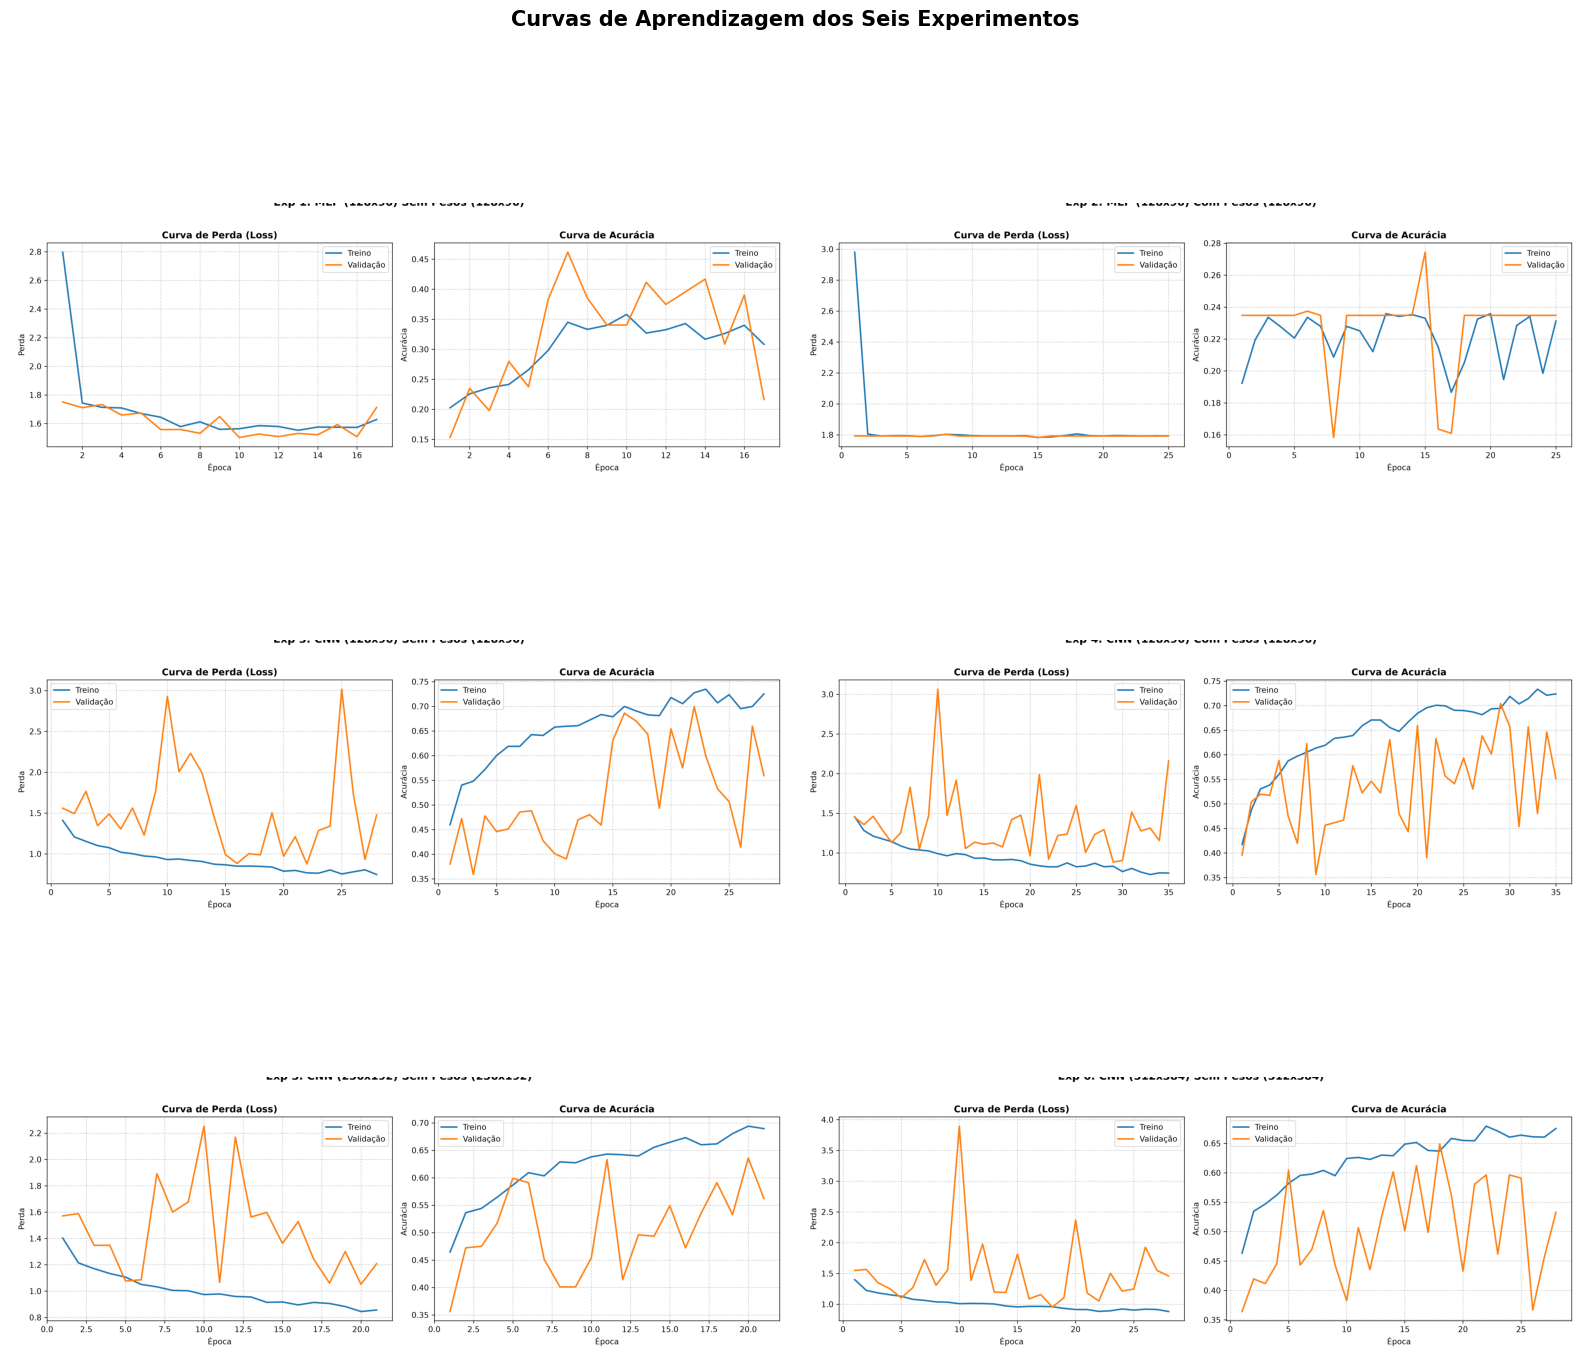

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes = axes.flatten()

for idx, exp_id in enumerate(range(1, 7)):
    curve_img_path = RESULTS_DIR / f"curves_exp_{exp_id}.png"
    if curve_img_path.exists():
        img = mpimg.imread(str(curve_img_path))
        axes[idx].imshow(img)
        axes[idx].axis("off")
    else:
        axes[idx].text(0.5, 0.5, f"Exp {exp_id} não executado", ha="center", va="center")
        axes[idx].axis("off")

plt.suptitle("Curvas de Aprendizagem dos Seis Experimentos", fontsize=15, fontweight="bold", y=1.001)
plt.tight_layout()
plt.show()

## 4. Matrizes de Confusão no Conjunto de Teste
Contagens absolutas e percentuais por linha na ordem: glass, paper, cardboard, plastic, metal, trash.

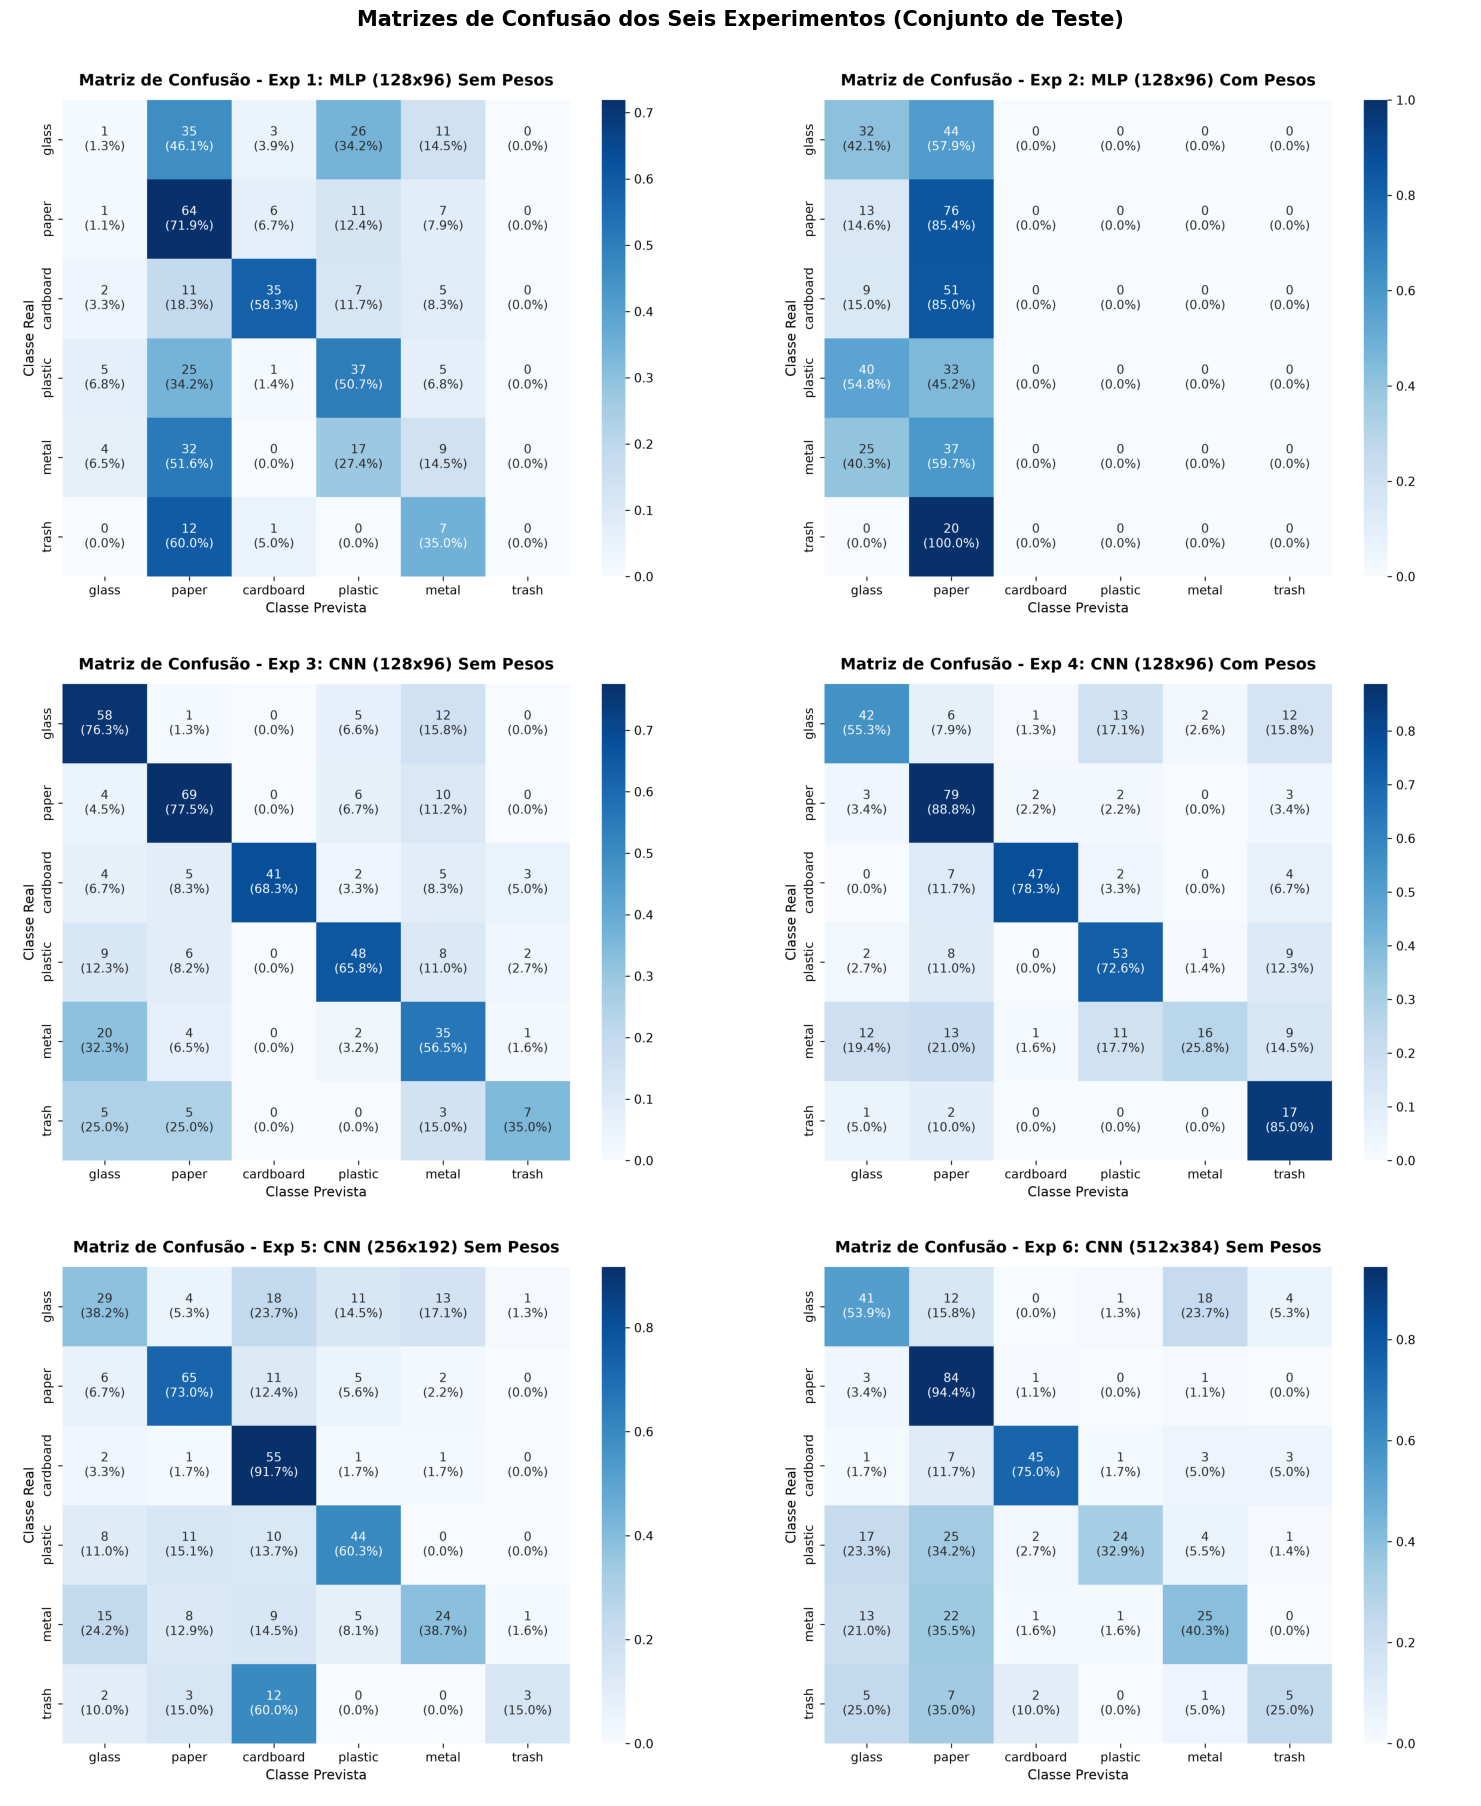

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()

for idx, exp_id in enumerate(range(1, 7)):
    cm_img_path = RESULTS_DIR / f"cm_exp_{exp_id}.png"
    if cm_img_path.exists():
        img = mpimg.imread(str(cm_img_path))
        axes[idx].imshow(img)
        axes[idx].axis("off")
    else:
        axes[idx].text(0.5, 0.5, f"Exp {exp_id} não executado", ha="center", va="center")
        axes[idx].axis("off")

plt.suptitle("Matrizes de Confusão dos Seis Experimentos (Conjunto de Teste)", fontsize=15, fontweight="bold", y=1.001)
plt.tight_layout()
plt.show()

## 5. Efeito da Resolução na CNN (128x96, 256x192, 512x384)
Comparando ganho de acurácia / F1-macro vs custo computacional (tempo por época e total).

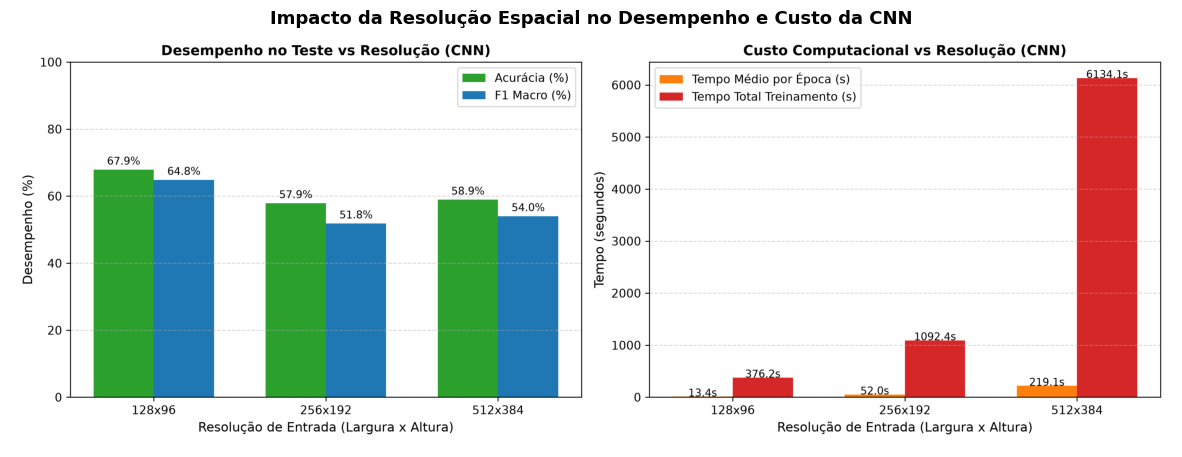

In [6]:
res_plot_path = RESULTS_DIR / "resolution_comparison.png"
if res_plot_path.exists():
    img = mpimg.imread(str(res_plot_path))
    plt.figure(figsize=(15, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Impacto da Resolução Espacial no Desempenho e Custo da CNN", fontsize=13, fontweight="bold")
    plt.show()
else:
    print("Gráfico resolution_comparison.png ainda não gerado.")

## 6. Análise de Erros do Melhor Modelo de Validação
Amostras de teste classificadas incorretamente com classe real, classe prevista e confiança atribuída.

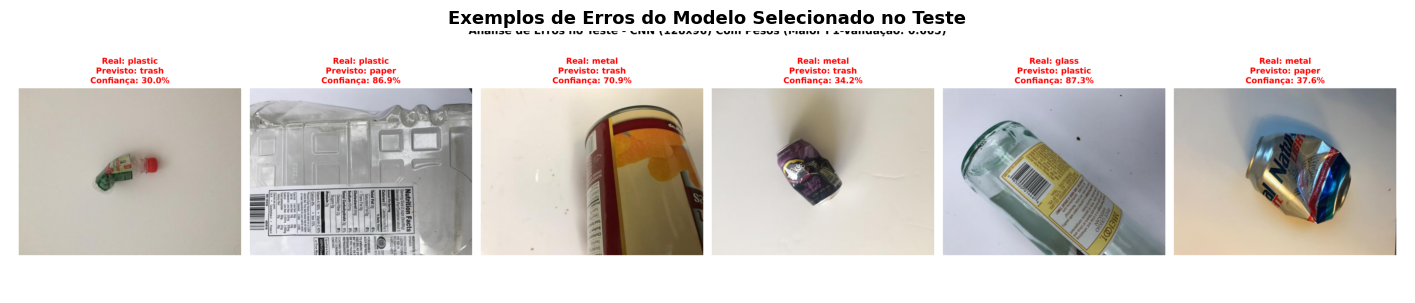

In [7]:
err_plot_path = RESULTS_DIR / "best_model_errors.png"
if err_plot_path.exists():
    img = mpimg.imread(str(err_plot_path))
    plt.figure(figsize=(18, 5.5))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Exemplos de Erros do Modelo Selecionado no Teste", fontsize=13, fontweight="bold")
    plt.show()
else:
    print("Gráfico best_model_errors.png ainda não gerado.")

## 7. Extensão Opcional: Transferência de Aprendizado com YOLOv8 Classify (Bônus)
Comparação direta no mesmo conjunto de teste entre a melhor CNN desenvolvida do zero e o modelo pré-treinado no ImageNet (YOLOv8n-cls).

In [8]:
yolo_json = RESULTS_DIR / 'yolo_summary.json'
if yolo_json.exists():
    with open(yolo_json, 'r', encoding='utf-8') as f:
        yd = json.load(f)
    print(f"Modelo: {yd['model']} | Pré-treinamento: {yd['pretraining']}")
    print(f"Acurácia no Teste: {yd['test_accuracy']*100:.2f}% | F1-Macro no Teste: {yd['test_f1_macro']*100:.2f}%")
    print(f"Tempo de Treinamento: {yd['total_time_seconds']}s ({yd['avg_epoch_time_seconds']}s/época)")
    rep_df = pd.DataFrame(yd['test_report']).transpose()
    display(rep_df.loc[['glass', 'paper', 'cardboard', 'plastic', 'metal', 'trash', 'macro avg', 'accuracy']])
else:
    print('yolo_summary.json não encontrado.')

Modelo: YOLOv8n-cls | Pré-treinamento: ImageNet-1k
Acurácia no Teste: 92.89% | F1-Macro no Teste: 91.65%
Tempo de Treinamento: 377.5s (15.1s/época)


,precision,recall,f1-score,support
glass,0.922078,0.934211,0.928105,76.000000
paper,0.943182,0.932584,0.937853,89.000000
cardboard,0.966667,0.966667,0.966667,60.000000
plastic,0.931507,0.931507,0.931507,73.000000
metal,0.948276,0.887097,0.916667,62.000000
trash,0.750000,0.900000,0.818182,20.000000
macro avg,0.910285,0.925344,0.916497,380.000000
accuracy,0.928947,0.928947,0.928947,0.928947


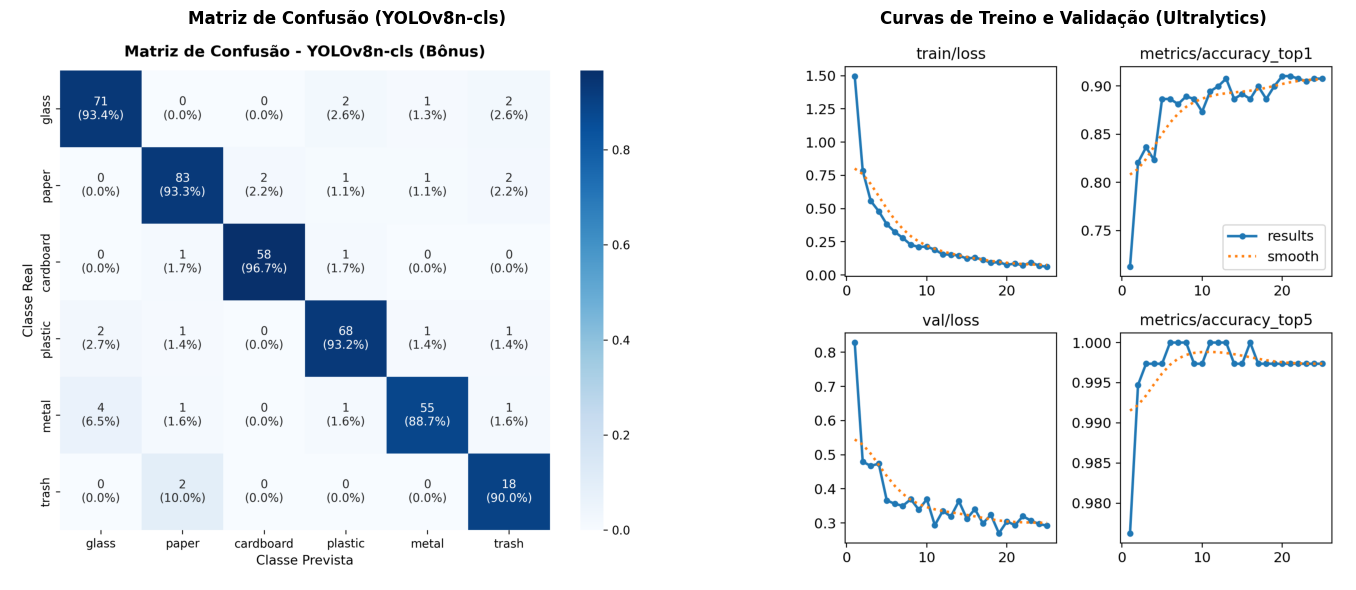

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
cm_yolo_path = RESULTS_DIR / 'cm_yolo.png'
curves_yolo_path = RESULTS_DIR / 'curves_yolo.png'
if cm_yolo_path.exists():
    ax1.imshow(mpimg.imread(str(cm_yolo_path)))
    ax1.axis('off')
    ax1.set_title('Matriz de Confusão (YOLOv8n-cls)', fontsize=12, fontweight='bold')
if curves_yolo_path.exists():
    ax2.imshow(mpimg.imread(str(curves_yolo_path)))
    ax2.axis('off')
    ax2.set_title('Curvas de Treino e Validação (Ultralytics)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()